# 3.1 Análisis de datos
NVDA, JPM y XOM: 500 días de entrenamiento + 20 días reservados para el backtest. Todo el análisis descriptivo usa **solo la ventana de entrenamiento** para no filtrar información del backtest.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import config, utils, plotstyle
plotstyle.apply()
pd.options.display.float_format = "{:.4f}".format

In [2]:
prices = utils.load_prices()
rets = utils.load_returns()
train, test = rets.iloc[:config.N_TRAIN], rets.iloc[config.N_TRAIN:]
print(f"Precios:          {prices.index[0].date()} -> {prices.index[-1].date()}")
print(f"Entrenamiento:    {train.index[0].date()} -> {train.index[-1].date()}  ({len(train)} días)")
print(f"Backtest:         {test.index[0].date()} -> {test.index[-1].date()}  ({len(test)} días)")
prices.tail()

Precios:          2024-10-21 -> 2026-11-17
Entrenamiento:    2024-10-22 -> 2026-10-20  (500 días)
Backtest:         2026-10-21 -> 2026-11-17  (20 días)


,NVDA,JPM,XOM
Date,,,
2026-11-11,173.7300,343.3900,165.6643
2026-11-12,166.1900,342.8200,168.7151
2026-11-13,162.8500,346.1900,169.5200
2026-11-16,156.1400,338.2100,166.8700
2026-11-17,155.4600,329.9600,167.2100


Cargamos precios y rendimientos y separamos las 500 observaciones de entrenamiento de las 20 del backtest.

Los datos cubren de oct-2024 a nov-2026; el entrenamiento termina el 2026-10-20 y el backtest abarca 20 días hábiles posteriores.

## Precios (base 100)

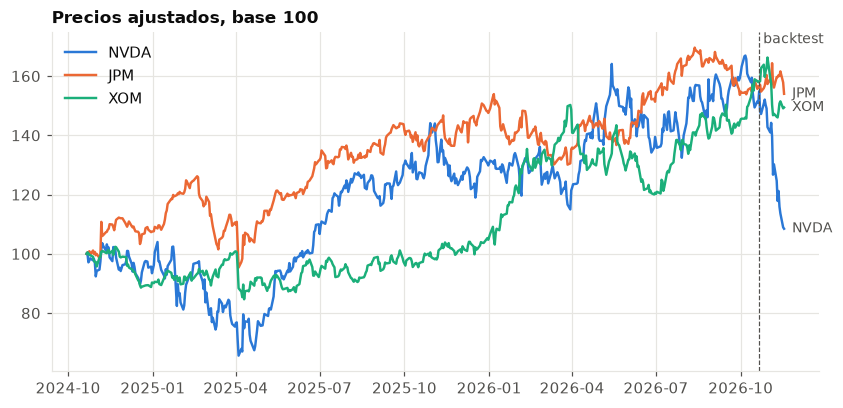

In [3]:
fig, ax = plt.subplots()
base = prices / prices.iloc[0] * 100
for t in config.TICKERS:
    ax.plot(base.index, base[t], color=plotstyle.ASSET_COLORS[t], label=t)
    ax.text(base.index[-1], base[t].iloc[-1], f"  {t}", color=plotstyle.INK2, va="center", fontsize=9)
ax.axvline(test.index[0], color=plotstyle.INK2, lw=0.8, ls="--")
ax.text(test.index[0], ax.get_ylim()[1], " backtest", color=plotstyle.INK2, va="top", fontsize=9)
ax.set_title("Precios ajustados, base 100"); ax.legend(loc="upper left")
plotstyle.save(fig, "01_precios"); plt.show()

Graficamos los precios ajustados con base 100 para comparar la trayectoria de los tres activos y marcamos dónde empieza el backtest.

Los tres activos terminan sobre su nivel inicial, pero con trayectorias distintas. NVDA es la más volátil y cae con fuerza en la ventana de backtest (pasa de arriba de 140 a debajo de 120); JPM y XOM se mueven de forma más estable.

## Rendimientos logarítmicos: estadísticos descriptivos (ventana de entrenamiento)

In [4]:
def describe(df):
    out = pd.DataFrame({
        "media diaria": df.mean(), "desv. diaria": df.std(),
        "asimetría": df.apply(stats.skew), "curtosis exceso": df.apply(stats.kurtosis),
        "mínimo": df.min(), "máximo": df.max(),
    })
    return out.T
describe(train)

,NVDA,JPM,XOM
media diaria,0.0008,0.0009,0.0009
desv. diaria,0.0276,0.0155,0.0157
asimetría,-0.3218,0.1044,-0.5116
curtosis exceso,6.8819,7.8494,1.7805
mínimo,-0.1859,-0.0778,-0.0747
máximo,0.1716,0.1093,0.0487


Calculamos media, desviación, asimetría, curtosis en exceso y extremos de los rendimientos log de entrenamiento.

Las medias son casi iguales (aprox. 0.09% diario), pero NVDA tiene casi el doble de desviación que JPM y XOM. La curtosis en exceso es positiva en los tres, sobre todo en JPM y NVDA; lo que implica que los rendimientos extremos ocurren con mayor frecuencia de lo que predice una normal con la misma media y desviación. 

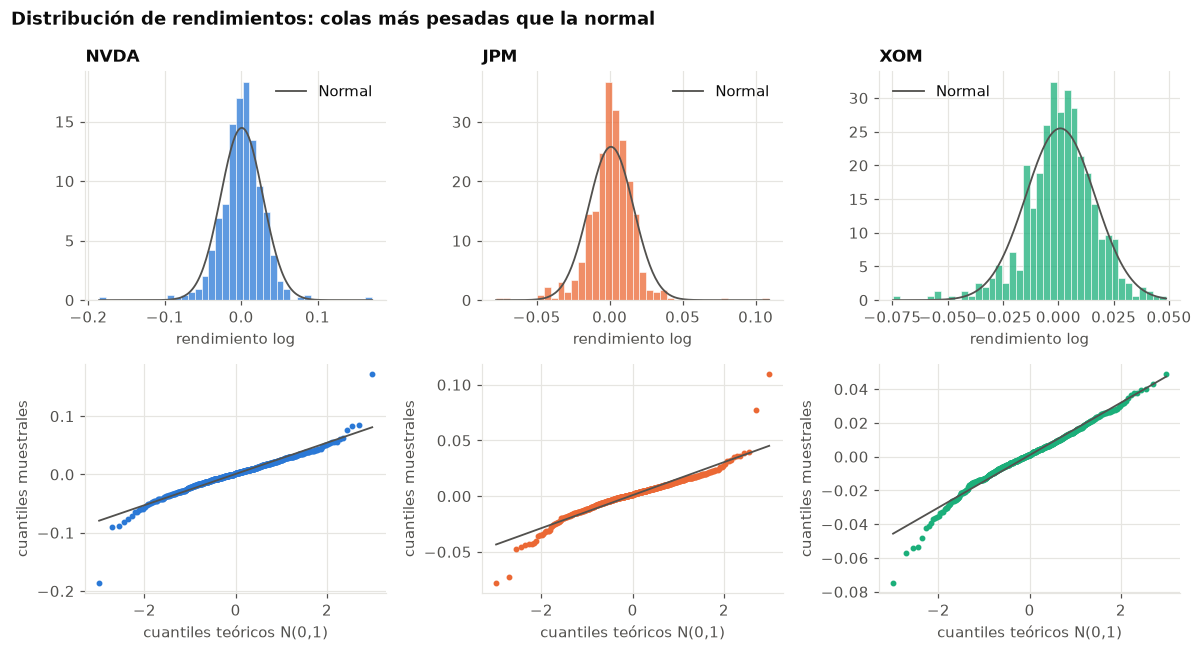

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for j, t in enumerate(config.TICKERS):
    x = train[t].values; c = plotstyle.ASSET_COLORS[t]
    ax = axes[0, j]
    ax.hist(x, bins=40, density=True, color=c, alpha=0.75, edgecolor="white", linewidth=0.5)
    g = np.linspace(x.min(), x.max(), 200)
    ax.plot(g, stats.norm.pdf(g, x.mean(), x.std()), color=plotstyle.INK2, lw=1.2, label="Normal")
    ax.set_title(t); ax.set_xlabel("rendimiento log"); ax.legend()
    ax = axes[1, j]
    (osm, osr), (slope, icpt, _) = stats.probplot(x, dist="norm")
    ax.scatter(osm, osr, s=8, color=c); ax.plot(osm, slope * osm + icpt, color=plotstyle.INK2, lw=1.2)
    ax.set_xlabel("cuantiles teóricos N(0,1)"); ax.set_ylabel("cuantiles muestrales")
fig.suptitle("Distribución de rendimientos: colas más pesadas que la normal", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plotstyle.save(fig, "01_distribuciones"); plt.show()

Comparamos el histograma de cada activo con una normal ajustada y revisamos el QQ-plot.

El pico central es más alto y las colas son más pesadas que las de la normal; en los QQ-plots los puntos extremos se alejan de la recta. XOM es el más cercano a la normalidad.

## Dependencia entre activos

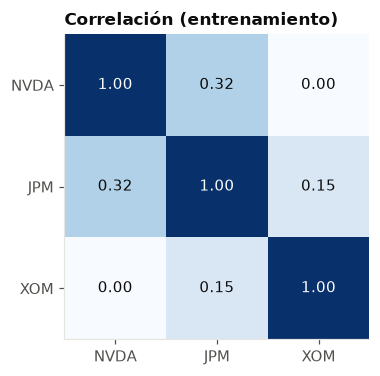

In [6]:
corr = train.corr()
fig, ax = plt.subplots(figsize=(4.2, 3.6))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3), config.TICKERS); ax.set_yticks(range(3), config.TICKERS); ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if corr.iloc[i, j] > 0.6 else plotstyle.INK)
ax.set_title("Correlación (entrenamiento)"); plotstyle.save(fig, "01_correlacion"); plt.show()

Calculamos y graficamos la matriz de correlación de los rendimientos de entrenamiento.

La dependencia es baja a moderada: JPM-NVDA 0.32, JPM-XOM 0.15 y NVDA-XOM ~0. Hay margen de diversificación.

## Portafolio equiponderado

In [7]:
port_train = pd.Series(utils.portfolio_return(train.values), index=train.index)
pd.DataFrame({
    "media diaria": [port_train.mean()], "desv. diaria": [port_train.std()],
    "asimetría": [stats.skew(port_train)], "curtosis exceso": [stats.kurtosis(port_train)],
    "VaR 95% histórico": [utils.var_es(port_train.values)[0]],
    "ES 95% histórico": [utils.var_es(port_train.values)[1]],
}, index=["Portafolio 1/3-1/3-1/3"]).T

,Portafolio 1/3-1/3-1/3
media diaria,0.0011
desv. diaria,0.0133
asimetría,0.3469
curtosis exceso,11.4105
VaR 95% histórico,0.0169
ES 95% histórico,0.0292


Construimos el portafolio con pesos 1/3 y calculamos sus estadísticos y el VaR y ES históricos al 95%.

La volatilidad del portafolio (1.33%) es menor que la de cada activo individual, pero su curtosis en exceso (11.4) es la más alta, así que el riesgo de cola persiste. El VaR 95% es 1.69% y el ES 95% es 2.92%.

## Observaciones
- **Dispersión muy distinta:** desviación diaria de 2.76% en NVDA frente a 1.55% en JPM y 1.57% en XOM.
- **Colas pesadas:** curtosis en exceso de 6.9 (NVDA), 7.8 (JPM) y 1.8 (XOM); el QQ-plot se separa de la recta en los extremos. El portafolio tiene curtosis en exceso de 11.4, lo que apunta a que un modelo normal subestimará las pérdidas extremas.
- **Diversificación real:** correlaciones de 0.32 (NVDA-JPM), 0.00 (NVDA-XOM) y 0.15 (JPM-XOM).
- **Referencia histórica (500 días):** VaR 95% = 1.69% y ES 95% = 2.92% del portafolio.